In [17]:
import pandas as pd

In [18]:
import numpy as np

In [19]:
df = pd.read_csv("/content/Airline Dataset.csv")
df

,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status
0,10856,Edithe,Leggis,Female,62,Japan,Coldfoot Airport,US,United States,NAM,North America,6/28/2022,CXF,Edithe Leggis,On Time
1,43872,Elwood,Catt,Male,62,Nicaragua,Kugluktuk Airport,CA,Canada,NAM,North America,12/26/2022,YCO,Elwood Catt,On Time
2,42633,Darby,Felgate,Male,67,Russia,Grenoble-Isère Airport,FR,France,EU,Europe,1/18/2022,GNB,Darby Felgate,On Time
3,78493,Dominica,Pyle,Female,71,China,Ottawa / Gatineau Airport,CA,Canada,NAM,North America,9/16/2022,YND,Dominica Pyle,Delayed
4,82072,Bay,Pencost,Male,21,China,Gillespie Field,US,United States,NAM,North America,2/25/2022,SEE,Bay Pencost,On Time
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98614,58454,Gareth,Mugford,Male,85,China,Hasvik Airport,NO,Norway,EU,Europe,12/11/2022,HAA,Gareth Mugford,Cancelled
98615,22028,Kasey,Benedict,Female,19,Russia,Ampampamena Airport,MG,Madagascar,AF,Africa,10/30/2022,IVA,Kasey Benedict,Cancelled
98616,61732,Darrin,Lucken,Male,65,Indonesia,Albacete-Los Llanos Airport,ES,Spain,EU,Europe,9/10/2022,ABC,Darrin Lucken,On Time
98617,19819,Gayle,Lievesley,Female,34,China,Gagnoa Airport,CI,Côte d'Ivoire,AF,Africa,10/26/2022,GGN,Gayle Lievesley,Cancelled


In [20]:
df.tail()

,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status
98614,58454,Gareth,Mugford,Male,85,China,Hasvik Airport,NO,Norway,EU,Europe,12/11/2022,HAA,Gareth Mugford,Cancelled
98615,22028,Kasey,Benedict,Female,19,Russia,Ampampamena Airport,MG,Madagascar,AF,Africa,10/30/2022,IVA,Kasey Benedict,Cancelled
98616,61732,Darrin,Lucken,Male,65,Indonesia,Albacete-Los Llanos Airport,ES,Spain,EU,Europe,9/10/2022,ABC,Darrin Lucken,On Time
98617,19819,Gayle,Lievesley,Female,34,China,Gagnoa Airport,CI,Côte d'Ivoire,AF,Africa,10/26/2022,GGN,Gayle Lievesley,Cancelled
98618,14485,Wilhelmine,Touret,Female,10,Poland,Yoshkar-Ola Airport,RU,Russian Federation,EU,Europe,4/16/2022,JOK,Wilhelmine Touret,Delayed


In [21]:
df.describe()

,Passenger ID,Age
count,98619.000000,98619.000000
mean,55168.689522,45.504021
std,25985.443696,25.929849
min,10000.000000,1.000000
25%,32608.000000,23.000000
50%,55338.000000,46.000000
75%,77695.000000,68.000000
max,99999.000000,90.000000


In [22]:
df.dtypes

,0
Passenger ID,int64
First Name,object
Last Name,object
Gender,object
Age,int64
Nationality,object
Airport Name,object
Airport Country Code,object
Country Name,object
Airport Continent,object


In [23]:
numeric_columns = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

In [24]:
print("\n Numeric Columns : ")
print(numeric_columns)


 Numeric Columns : 
['Passenger ID', 'Age']


In [25]:
print("\n categorical Columns : ")
print(categorical_columns)


 categorical Columns : 
['First Name', 'Last Name', 'Gender', 'Nationality', 'Airport Name', 'Airport Country Code', 'Country Name', 'Airport Continent', 'Continents', 'Departure Date', 'Arrival Airport', 'Pilot Name', 'Flight Status']


In [26]:
#Performing Data Cleaning
#• Handing Missing Data
#• Removing Null data

In [27]:
#Show initial missing value count
print("Missing Values Before Cleaning : ")
print(df.isnull().sum())

Missing Values Before Cleaning : 
Passenger ID            0
First Name              0
Last Name               0
Gender                  0
Age                     0
Nationality             0
Airport Name            0
Airport Country Code    0
Country Name            0
Airport Continent       0
Continents              0
Departure Date          0
Arrival Airport         0
Pilot Name              0
Flight Status           0
dtype: int64


In [29]:
from sklearn.preprocessing import MinMaxScaler

X = df[['Passenger ID', 'Age']]

scaler = MinMaxScaler()
rescaled_data = scaler.fit_transform(X)

rescaled_df = pd.DataFrame(rescaled_data, columns=['Passenger ID', 'Age'])
print(rescaled_df.head())

   Passenger ID       Age
0      0.009511  0.685393
1      0.376360  0.685393
2      0.362593  0.741573
3      0.761042  0.786517
4      0.800809  0.224719


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder object
encoder = LabelEncoder()

# Encoder categorical column
df['car name'] = encoder.fit_transform(df['car name'])

# Display encoder data
print(df[['car name']].head())

In [30]:
from sklearn.preprocessing import LabelEncoder

# Departure Date se month nikaal lo (date ko directly encode karna sahi nahi)
df['Departure Date'] = pd.to_datetime(df['Departure Date'], errors='coerce')
df['Departure Month'] = df['Departure Date'].dt.month

df_encoded = df.copy()
encoder = LabelEncoder()

cols_to_encode = ['First Name', 'Last Name', 'Gender', 'Nationality', 'Airport Name',
                  'Airport Country Code', 'Country Name', 'Airport Continent',
                  'Continents', 'Arrival Airport', 'Pilot Name', 'Flight Status']

for col in cols_to_encode:
    df_encoded[col] = encoder.fit_transform(df_encoded[col])

print(df_encoded[cols_to_encode].head())

   First Name  Last Name  Gender  Nationality  Airport Name  \
0        2487      22626       0          105          1717   
1        2629       6478       1          152          4228   
2        2023      12947       1          177          3034   
3        2298      31198       0           43          6031   
4         828      29617       1           43          2870   

   Airport Country Code  Country Name  Airport Continent  Continents  \
0                   219           221                  3           3   
1                    34            37                  3           3   
2                    70            72                  2           2   
3                    34            37                  3           3   
4                   219           221                  3           3   

   Arrival Airport  Pilot Name  Flight Status  
0             1657       29123              2  
1             8499       30724              2  
2             2679       23677              

Explained variance ratio: [0.25291438 0.12581038]


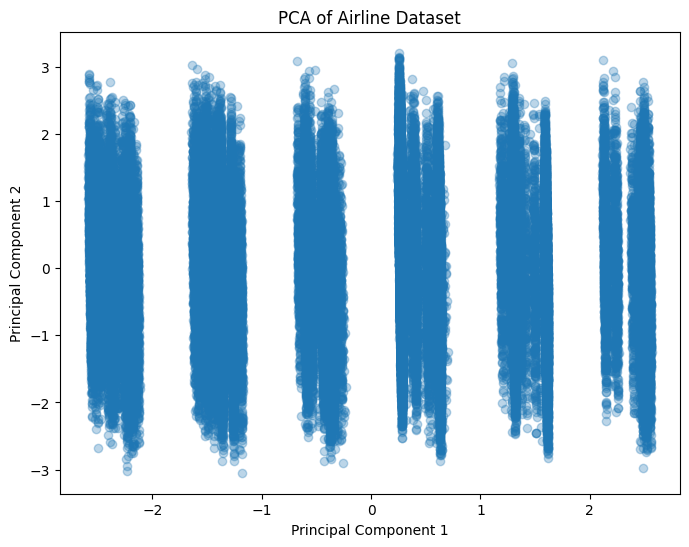

In [33]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

features = ['Age', 'Gender', 'Nationality', 'Airport Country Code',
            'Airport Continent', 'Continents', 'Departure Month', 'Flight Status']

X = df_encoded[features]
X = X.fillna(X.mean())

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(principal_components[:, 0], principal_components[:, 1], alpha=0.3)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Airline Dataset")
plt.show()